In [1]:

import pandas as pd

# Titanic 데이터 불러오기
df = pd.read_csv('/content/train.csv')

# 데이터 크기 확인
print("데이터 크기:", df.shape)

# 처음 5개 데이터 확인
display(df.head())

# 데이터 정보 확인
df.info()

# 결측치 확인
print("\n결측치 개수:")
print(df.isnull().sum())


데이터 크기: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

결측치 개수:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: 

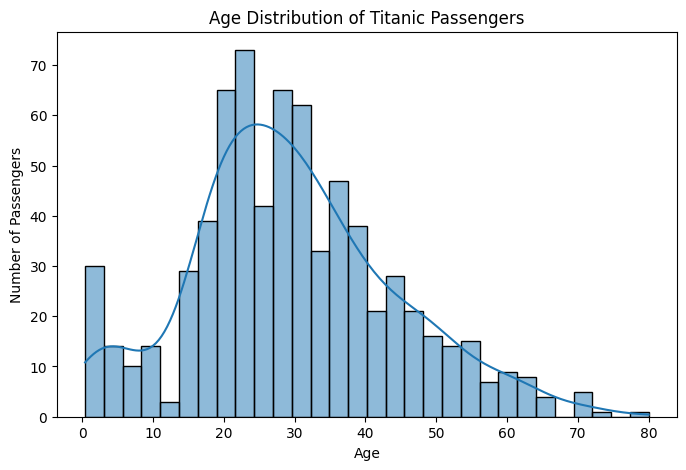

In [2]:

import matplotlib.pyplot as plt
import seaborn as sns

# STEP 02 - Histogram
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='Age',
    bins=30,
    kde=True
)

plt.title('Age Distribution of Titanic Passengers')
plt.xlabel('Age')
plt.ylabel('Number of Passengers')

plt.show()


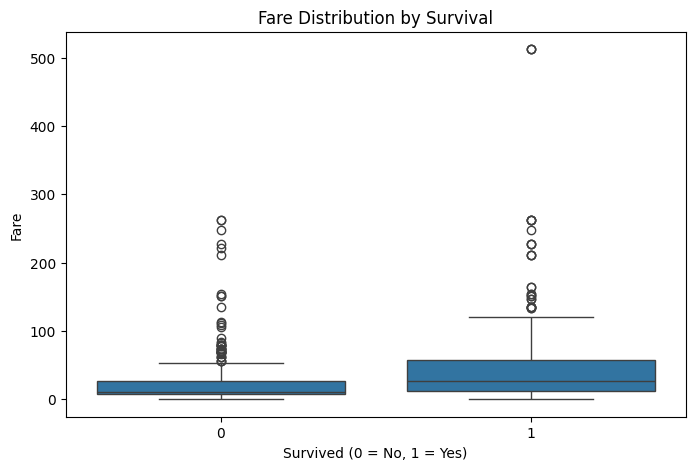

In [3]:

# STEP 02 - Boxplot
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Survived',
    y='Fare'
)

plt.title('Fare Distribution by Survival')
plt.xlabel('Survived (0 = No, 1 = Yes)')
plt.ylabel('Fare')

plt.show()


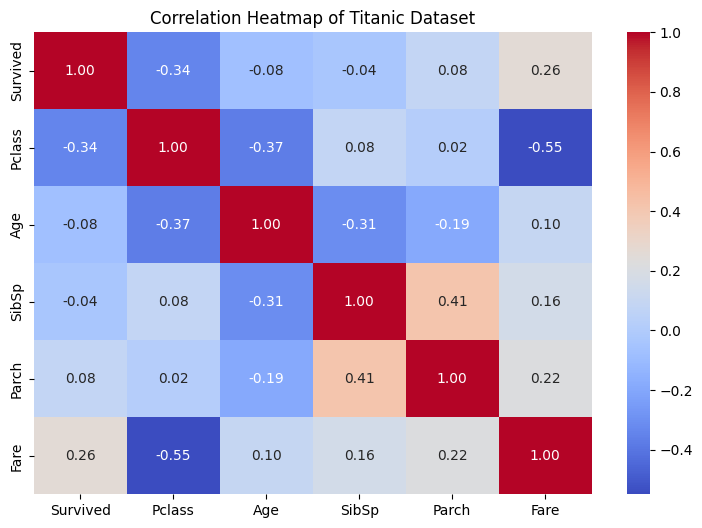

In [4]:

# STEP 02 - Heatmap
plt.figure(figsize=(9, 6))

# 수치형 변수 선택
numeric_df = df[
    ['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
]

# 상관관계 계산
correlation = numeric_df.corr()

# Heatmap 그리기
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Titanic Dataset')
plt.show()


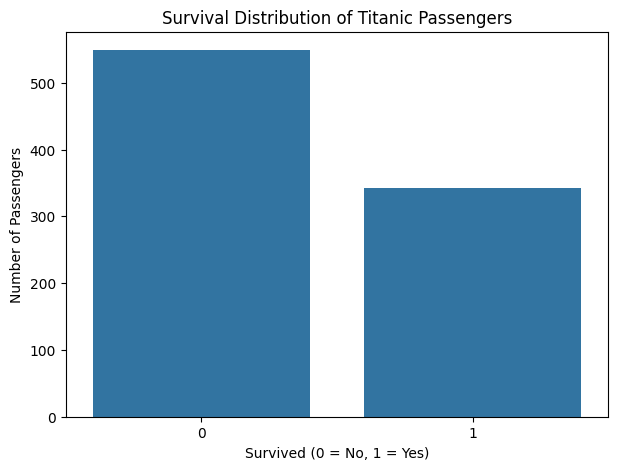

Survived
0    549
1    342
Name: count, dtype: int64


In [5]:

# STEP 02 - Countplot
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='Survived'
)

plt.title('Survival Distribution of Titanic Passengers')
plt.xlabel('Survived (0 = No, 1 = Yes)')
plt.ylabel('Number of Passengers')

plt.show()

# 생존자와 사망자 수 확인
print(df['Survived'].value_counts())


In [6]:

# STEP 02 - 결측치 비율 분석
missing = pd.DataFrame({
    '결측치 개수': df.isnull().sum(),
    '결측치 비율(%)': (df.isnull().mean() * 100).round(2)
})

print("=== 결측치 분석 ===")
display(missing)

# IQR 방법으로 이상치 분석
def count_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    return ((data < Q1 - 1.5 * IQR) |
            (data > Q3 + 1.5 * IQR)).sum()

print("=== 이상치 분석 ===")
for col in ['Age', 'Fare', 'SibSp', 'Parch']:
    print(col, ":", count_outliers(df[col]))


=== 결측치 분석 ===


,결측치 개수,결측치 비율(%)
PassengerId,0,0.00
Survived,0,0.00
Pclass,0,0.00
Name,0,0.00
Sex,0,0.00
Age,177,19.87
SibSp,0,0.00
Parch,0,0.00
Ticket,0,0.00
Fare,0,0.00


=== 이상치 분석 ===
Age : 11
Fare : 116
SibSp : 46
Parch : 213


In [7]:

# STEP 03 - Feature Engineering

# 원본 데이터 복사
df_fe = df.copy()

# 1. 가족 크기
df_fe['FamilySize'] = (
    df_fe['SibSp'] + df_fe['Parch'] + 1
)

# 2. 혼자 탑승했는지 여부
df_fe['IsAlone'] = (
    df_fe['FamilySize'] == 1
).astype(int)

# 3. 1인당 운임
df_fe['FarePerPerson'] = (
    df_fe['Fare'] / df_fe['FamilySize']
)

# 새로운 변수 확인
display(
    df_fe[
        ['SibSp', 'Parch', 'Fare',
         'FamilySize', 'IsAlone',
         'FarePerPerson']
    ].head(10)
)

print("데이터 크기:", df_fe.shape)


,SibSp,Parch,Fare,FamilySize,IsAlone,FarePerPerson
0,1,0,7.2500,2,0,3.62500
1,1,0,71.2833,2,0,35.64165
2,0,0,7.9250,1,1,7.92500
3,1,0,53.1000,2,0,26.55000
4,0,0,8.0500,1,1,8.05000
5,0,0,8.4583,1,1,8.45830
6,0,0,51.8625,1,1,51.86250
7,3,1,21.0750,5,0,4.21500
8,0,2,11.1333,3,0,3.71110
9,1,0,30.0708,2,0,15.03540


데이터 크기: (891, 15)


In [8]:

# STEP 03-2 결측치 처리 비교

from sklearn.impute import SimpleImputer
import pandas as pd

# Age 변수의 결측치 처리 방법 비교
methods = ['mean', 'median', 'most_frequent']

results = []

for method in methods:
    imputer = SimpleImputer(strategy=method)

    age_filled = imputer.fit_transform(
        df_fe[['Age']]
    )

    results.append({
        'Method': method,
        'Filled Value': round(
            imputer.statistics_[0], 2
        ),
        'Missing After': pd.isna(
            age_filled
        ).sum()
    })

result_df = pd.DataFrame(results)

print("=== 결측치 처리 방법 비교 ===")
display(result_df)


=== 결측치 처리 방법 비교 ===


,Method,Filled Value,Missing After
0,mean,29.7,0
1,median,28.0,0
2,most_frequent,24.0,0


In [9]:

# STEP 03-3 범주형 인코딩 비교

from sklearn.preprocessing import LabelEncoder, OneHotEncoder

# 원본 성별 데이터
print("=== 원본 데이터 ===")
display(df_fe[['Sex']].head())

# 1. Label Encoding
label_encoder = LabelEncoder()
label_result = label_encoder.fit_transform(df_fe['Sex'])

print("\n=== Label Encoding ===")
label_df = pd.DataFrame({
    'Sex': df_fe['Sex'],
    'Label_Encoded': label_result
})
display(label_df.head())

# 2. One-Hot Encoding
onehot_result = pd.get_dummies(
    df_fe['Sex'],
    prefix='Sex',
    dtype=int
)

print("\n=== One-Hot Encoding ===")
display(onehot_result.head())

# 인코딩 후 변수 개수 비교
print("\n=== 변수 개수 비교 ===")
print("Label Encoding: 1개")
print("One-Hot Encoding:", onehot_result.shape[1], "개")


=== 원본 데이터 ===


,Sex
0,male
1,female
2,female
3,female
4,male



=== Label Encoding ===


,Sex,Label_Encoded
0,male,1
1,female,0
2,female,0
3,female,0
4,male,1



=== One-Hot Encoding ===


,Sex_female,Sex_male
0,0,1
1,1,0
2,1,0
3,1,0
4,0,1



=== 변수 개수 비교 ===
Label Encoding: 1개
One-Hot Encoding: 2 개


In [10]:

# STEP 03-4 스케일링 방법 비교

from sklearn.preprocessing import (
    StandardScaler, MinMaxScaler, RobustScaler
)

# 결측치가 없는 Fare 변수 사용
fare_data = df_fe[['Fare']]

scalers = {
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler(),
    'RobustScaler': RobustScaler()
}

scaling_results = pd.DataFrame({
    'Original_Fare': df_fe['Fare']
})

for name, scaler in scalers.items():
    scaling_results[name] = scaler.fit_transform(
        fare_data
    ).flatten()

print("=== 스케일링 방법 비교 ===")
display(scaling_results.head(10))

# 통계값 비교
print("\n=== 스케일링 결과 통계 ===")
display(scaling_results.describe().round(2))


=== 스케일링 방법 비교 ===


,Original_Fare,StandardScaler,MinMaxScaler,RobustScaler
0,7.2500,-0.502445,0.014151,-0.312011
1,71.2833,0.786845,0.139136,2.461242
2,7.9250,-0.488854,0.015469,-0.282777
3,53.1000,0.420730,0.103644,1.673732
4,8.0500,-0.486337,0.015713,-0.277363
5,8.4583,-0.478116,0.016510,-0.259680
6,51.8625,0.395814,0.101229,1.620136
7,21.0750,-0.224083,0.041136,0.286744
8,11.1333,-0.424256,0.021731,-0.143827
9,30.0708,-0.042956,0.058694,0.676348



=== 스케일링 결과 통계 ===


,Original_Fare,StandardScaler,MinMaxScaler,RobustScaler
count,891.00,891.00,891.00,891.00
mean,32.20,0.00,0.06,0.77
std,49.69,1.00,0.10,2.15
min,0.00,-0.65,0.00,-0.63
25%,7.91,-0.49,0.02,-0.28
50%,14.45,-0.36,0.03,0.00
75%,31.00,-0.02,0.06,0.72
max,512.33,9.67,1.00,21.56


In [11]:

# STEP 04 - Feature Selection

from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

# 입력 변수와 타겟 변수 설정
X = df_fe[
    ['Pclass', 'Age', 'SibSp', 'Parch',
     'Fare', 'FamilySize', 'IsAlone',
     'FarePerPerson', 'Sex', 'Embarked']
]

y = df_fe['Survived']

# 훈련 데이터와 테스트 데이터 분리
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 수치형 변수
num_cols = [
    'Pclass', 'Age', 'SibSp', 'Parch',
    'Fare', 'FamilySize', 'IsAlone',
    'FarePerPerson'
]

# 수치형 결측치 처리
imputer = SimpleImputer(strategy='median')

X_train_num = pd.DataFrame(
    imputer.fit_transform(X_train[num_cols]),
    columns=num_cols,
    index=X_train.index
)

# 중요도 상위 5개 변수 선택
selector = SelectKBest(
    score_func=f_classif,
    k=5
)

selector.fit(X_train_num, y_train)

selected_features = X_train_num.columns[
    selector.get_support()
]

print("=== 선택된 상위 5개 변수 ===")
print(selected_features.tolist())

# 변수별 점수
scores = pd.DataFrame({
    'Feature': num_cols,
    'Score': selector.scores_
}).sort_values('Score', ascending=False)

display(scores)


=== 선택된 상위 5개 변수 ===
['Pclass', 'Parch', 'Fare', 'IsAlone', 'FarePerPerson']


,Feature,Score
0,Pclass,97.835853
4,Fare,58.314907
7,FarePerPerson,36.799008
6,IsAlone,34.601859
3,Parch,5.066904
1,Age,3.779379
5,FamilySize,0.516703
2,SibSp,0.484537


In [12]:

# STEP 05 - 모델 학습 및 성능 비교

from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score
)

# 모델별 결과 저장
results = []

models = {
    'Logistic Regression': LogisticRegression(
        max_iter=2000, random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, random_state=42
    )
}

# Feature Selection 적용 전후 비교
for model_name, model in models.items():
    for use_selection in [False, True]:

        steps = [
            ('imputer', SimpleImputer(strategy='median'))
        ]

        if use_selection:
            steps.append(
                ('selection', SelectKBest(
                    score_func=f_classif, k=5
                ))
            )

        steps.append(('model', model))

        pipeline = Pipeline(steps)

        pipeline.fit(X_train[num_cols], y_train)

        y_pred = pipeline.predict(X_test[num_cols])
        y_prob = pipeline.predict_proba(
            X_test[num_cols]
        )[:, 1]

        results.append({
            'Model': model_name,
            'Feature Selection':
                'Yes' if use_selection else 'No',
            'Accuracy': accuracy_score(y_test, y_pred),
            'Precision': precision_score(y_test, y_pred),
            'Recall': recall_score(y_test, y_pred),
            'F1': f1_score(y_test, y_pred),
            'ROC-AUC': roc_auc_score(y_test, y_prob)
        })

fs_results = pd.DataFrame(results)

print("=== Feature Selection 성능 비교 ===")
display(fs_results.round(4))


=== Feature Selection 성능 비교 ===


,Model,Feature Selection,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,No,0.6872,0.6383,0.4348,0.5172,0.7454
1,Logistic Regression,Yes,0.6592,0.5690,0.4783,0.5197,0.6907
2,Random Forest,No,0.5922,0.4730,0.5072,0.4895,0.6375
3,Random Forest,Yes,0.5978,0.4795,0.5072,0.4930,0.6553


In [13]:

# STEP 05 - Base / Exp-1 / Exp-2 / Exp-3 비교

import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OneHotEncoder, OrdinalEncoder,
    StandardScaler, MinMaxScaler, RobustScaler
)
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score
)

# 비교할 변수
numeric_cols = [
    'Pclass', 'Age', 'SibSp', 'Parch',
    'Fare', 'FamilySize', 'IsAlone',
    'FarePerPerson'
]
categorical_cols = ['Sex', 'Embarked']

# 앞에서 만든 동일한 학습/테스트 분할 사용
Xtr = X_train[numeric_cols + categorical_cols]
Xte = X_test[numeric_cols + categorical_cols]

experiment_results = []

def evaluate_experiment(name, pipeline, X_train_data, X_test_data):
    pipeline.fit(X_train_data, y_train)

    pred = pipeline.predict(X_test_data)
    prob = pipeline.predict_proba(X_test_data)[:, 1]

    model_name = pipeline.named_steps['model'].__class__.__name__

    experiment_results.append({
        'Experiment': name,
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1': f1_score(y_test, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, prob)
    })

models = {
    'LR': LogisticRegression(max_iter=3000, random_state=42),
    'RF': RandomForestClassifier(
        n_estimators=200, random_state=42
    )
}

# Base: 결측치 없는 원본 수치형 변수만 사용
base_cols = ['Pclass', 'SibSp', 'Parch', 'Fare']

for model_key, model in models.items():
    base_pipe = Pipeline([
        ('model', model)
    ])
    evaluate_experiment(
        'Base', base_pipe,
        X_train[base_cols], X_test[base_cols]
    )

# 3개 실험 설정
experiments = {
    'Exp-1': ('mean', 'onehot', StandardScaler(), False),
    'Exp-2': ('median', 'ordinal', MinMaxScaler(), True),
    'Exp-3': ('most_frequent', 'onehot', RobustScaler(), True)
}

for exp_name, (missing, encoding, scaler, selection) in experiments.items():

    if encoding == 'onehot':
        encoder = OneHotEncoder(
            handle_unknown='ignore'
        )
    else:
        encoder = OrdinalEncoder(
            handle_unknown='use_encoded_value',
            unknown_value=-1
        )

    preprocessing = ColumnTransformer([
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy=missing)),
            ('scaler', scaler)
        ]), numeric_cols),

        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', encoder)
        ]), categorical_cols)
    ])

    for model_key, model in models.items():
        steps = [('preprocessing', preprocessing)]

        if selection:
            steps.append(
                ('selection', SelectKBest(
                    score_func=f_classif, k=5
                ))
            )

        steps.append(('model', model))

        pipe = Pipeline(steps)

        evaluate_experiment(exp_name, pipe, Xtr, Xte)

# 최종 결과 출력
final_results = pd.DataFrame(experiment_results)

print("=== 최종 실험 성능 비교 ===")
display(final_results.round(4))

# CSV 저장
final_results.to_csv(
    'final_experiment_results.csv',
    index=False
)


=== 최종 실험 성능 비교 ===


,Experiment,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Base,LogisticRegression,0.6480,0.5625,0.3913,0.4615,0.6742
1,Base,RandomForestClassifier,0.5922,0.4714,0.4783,0.4748,0.6450
2,Exp-1,LogisticRegression,0.8045,0.7833,0.6812,0.7287,0.8499
3,Exp-1,RandomForestClassifier,0.7765,0.7231,0.6812,0.7015,0.8174
4,Exp-2,LogisticRegression,0.7821,0.7419,0.6667,0.7023,0.8182
5,Exp-2,RandomForestClassifier,0.7709,0.7059,0.6957,0.7007,0.8248
6,Exp-3,LogisticRegression,0.7821,0.7419,0.6667,0.7023,0.8142
7,Exp-3,RandomForestClassifier,0.7709,0.7059,0.6957,0.7007,0.8303


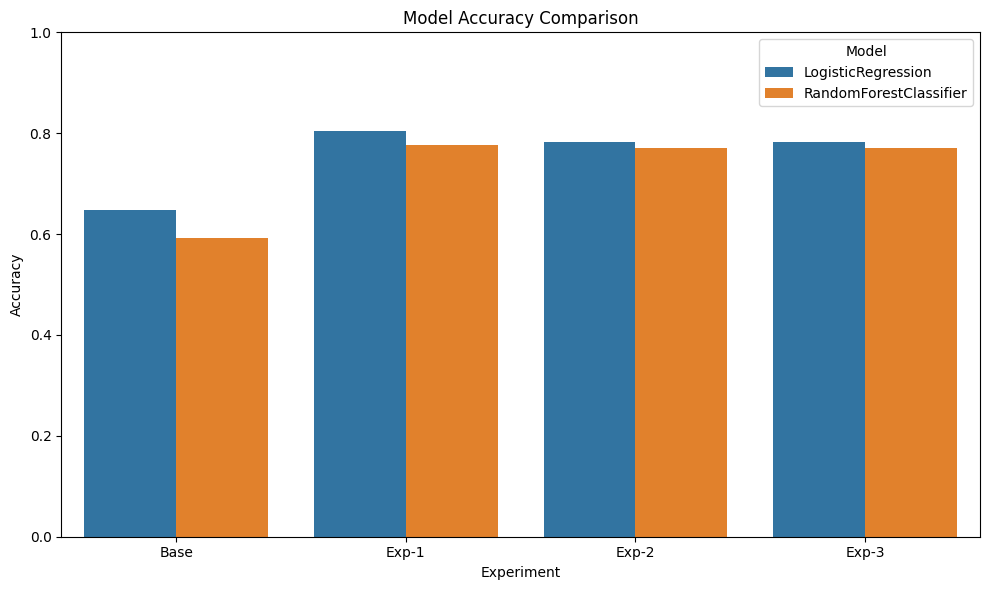

In [14]:

# 최종 실험 Accuracy 비교 그래프

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=final_results,
    x='Experiment',
    y='Accuracy',
    hue='Model'
)

plt.title('Model Accuracy Comparison')
plt.xlabel('Experiment')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.legend(title='Model')
plt.tight_layout()

plt.savefig(
    'model_accuracy_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()
